<a href="https://colab.research.google.com/github/lekshmidhiya/Exp-2/blob/main/Retail_Sales_Performance_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Retail Sales Performance Analysis

### Project Overview

This project focuses on analysing retail sales data to understand business performance, identify sales trends, evaluate product profitability, and discover important business insights.

### Objectives
- Analyse overall sales and profit.
- Identify yearly and monthly sales trends.
- Evaluate product category performance.
- Analyse regional and customer segment performance.
- Understand the impact of discounts on profit.
- Present insights using data visualizations.

### Dataset
Global Superstore Dataset

**Tools Used:** Python, Pandas, Matplotlib, Google Colab


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Global_Superstore2.csv to Global_Superstore2.csv



## 1. Importing Required Libraries

The following Python libraries are used for data manipulation, analysis, and visualization.

- **Pandas:** Data cleaning and analysis.
- **Matplotlib:** Creating charts and visualizations.



## 2. Dataset Loading

The Global Superstore dataset is loaded using the Pandas library.

The dataset contains retail transaction details, including order dates, customer information, product categories, sales, discounts, and profits.

The dataset is used to analyse overall business performance and identify important trends.


In [ ]:
import pandas as pd

df = pd.read_csv('Global_Superstore2.csv', encoding='latin1')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (51290, 24)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,32298,CA-2012-124891,31-07-2012,31-07-2012,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,2309.650,7,0.0,762.1845,933.57,Critical
1,26341,IN-2013-77878,05-02-2013,07-02-2013,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",3709.395,9,0.1,-288.7650,923.63,Critical
2,25330,IN-2013-71249,17-10-2013,18-10-2013,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID",5175.171,9,0.1,919.9710,915.49,Medium
3,13524,ES-2013-1579342,28-01-2013,30-01-2013,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless",2892.510,5,0.1,-96.5400,910.16,Medium
4,47221,SG-2013-4320,05-11-2013,06-11-2013,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed",2832.960,8,0.0,311.5200,903.04,Critical



## 3. Data Cleaning and Preprocessing

The dataset was checked for missing values and duplicate records. Unnecessary columns were removed, and date columns were converted into the appropriate format for analysis.


In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'City', 'State', 'Country', 'Postal Code', 'Market', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Cost', 'Order Priority']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          51290 non-null  int64  
 1   Order ID        51290 non-null  object 
 2   Order Date      51290 non-null  object 
 3   Ship Date       51290 non-null  object 
 4   Ship Mode       51290 non-null  object 
 5   Customer ID     51290 non-null  object 
 6   Customer Name   51290 non-null  object 
 7   Segment         51290 non-null  object 
 8   City            51290 non-null  object 
 9   State           51290 non-null  object 
 10  Count

In [ ]:
# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Summary of numerical columns
print("\nNumerical data summary:")
display(df.describe())

Duplicate rows: 0

Numerical data summary:


,Row ID,Postal Code,Sales,Quantity,Discount,Profit,Shipping Cost
count,51290.00000,9994.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000
mean,25645.50000,55190.379428,246.490581,3.476545,0.142908,28.610982,26.375915
std,14806.29199,32063.693350,487.565361,2.278766,0.212280,174.340972,57.296804
min,1.00000,1040.000000,0.444000,1.000000,0.000000,-6599.978000,0.000000
25%,12823.25000,23223.000000,30.758625,2.000000,0.000000,0.000000,2.610000
50%,25645.50000,56430.500000,85.053000,3.000000,0.000000,9.240000,7.790000
75%,38467.75000,90008.000000,251.053200,5.000000,0.200000,36.810000,24.450000
max,51290.00000,99301.000000,22638.480000,14.000000,0.850000,8399.976000,933.570000


In [ ]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values[missing_values > 0])

# Calculate missing percentage
print("\nMissing percentage:")
print((missing_values[missing_values > 0] / len(df) * 100).round(2))

Missing values in each column:
Postal Code    41296
dtype: int64

Missing percentage:
Postal Code    80.51
dtype: float64


In [ ]:
df = df.drop(columns=['Postal Code'])

print("Postal Code column removed.")
print("Updated dataset shape:", df.shape)

Postal Code column removed.
Updated dataset shape: (51290, 23)


In [ ]:
print("Missing values after cleaning:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nFinal dataset shape:")
print(df.shape)

Missing values after cleaning:
0

Duplicate rows:
0

Final dataset shape:
(51290, 23)


In [ ]:
df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=True)
df['Ship Date'] = pd.to_datetime(df['Ship Date'], dayfirst=True)

print(df[['Order Date', 'Ship Date']].dtypes)

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [ ]:
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month
df['Month Name'] = df['Order Date'].dt.month_name()

df[['Order Date', 'Year', 'Month', 'Month Name']].head()

,Order Date,Year,Month,Month Name
0,2012-07-31,2012,7,July
1,2013-02-05,2013,2,February
2,2013-10-17,2013,10,October
3,2013-01-28,2013,1,January
4,2013-11-05,2013,11,November


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          51290 non-null  int64         
 1   Order ID        51290 non-null  object        
 2   Order Date      51290 non-null  datetime64[ns]
 3   Ship Date       51290 non-null  datetime64[ns]
 4   Ship Mode       51290 non-null  object        
 5   Customer ID     51290 non-null  object        
 6   Customer Name   51290 non-null  object        
 7   Segment         51290 non-null  object        
 8   City            51290 non-null  object        
 9   State           51290 non-null  object        
 10  Country         51290 non-null  object        
 11  Market          51290 non-null  object        
 12  Region          51290 non-null  object        
 13  Product ID      51290 non-null  object        
 14  Category        51290 non-null  object        
 15  Su


## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the dataset and identify important patterns in sales, profit, products, customers, and business performance.


In [ ]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_quantity = df['Quantity'].sum()
total_orders = df['Order ID'].nunique()

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Quantity Sold:", total_quantity)
print("Total Orders:", total_orders)

Total Sales: 12642501.91
Total Profit: 1467457.29
Total Quantity Sold: 178312
Total Orders: 25035



## 5. Sales Trend Analysis

Yearly and monthly sales are analysed to identify sales growth patterns and seasonal trends over time.


In [ ]:
yearly_sales = df.groupby('Year')['Sales'].sum()

print(yearly_sales)

Year
2011    2.259451e+06
2012    2.677439e+06
2013    3.405746e+06
2014    4.299866e+06
Name: Sales, dtype: float64


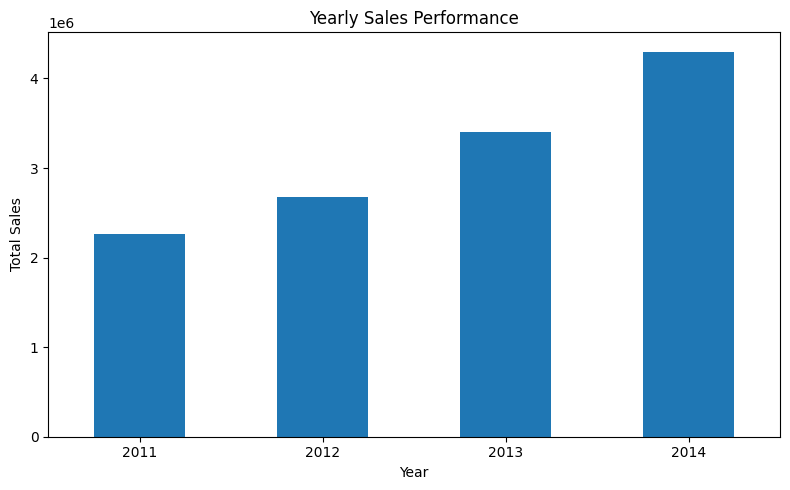

In [ ]:
import matplotlib.pyplot as plt

yearly_sales.plot(kind='bar', figsize=(8, 5))

plt.title('Yearly Sales Performance')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
monthly_sales = df.groupby('Month Name')['Sales'].sum()

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_sales = monthly_sales.reindex(month_order)

print(monthly_sales.round(2))

Month Name
January       675133.67
February      543739.38
March         770500.94
April         698561.21
May           904012.34
June         1269716.75
July          749381.84
August       1293833.17
September    1437380.11
October      1168184.39
November     1551277.34
December     1580780.77
Name: Sales, dtype: float64


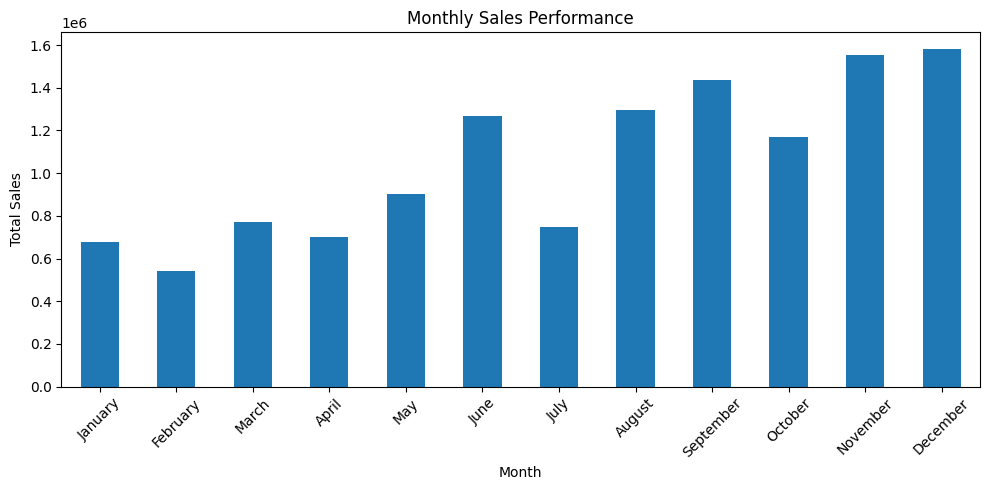

In [ ]:
monthly_sales.plot(kind='bar', figsize=(10, 5))

plt.title('Monthly Sales Performance')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 6. Product Performance Analysis

Product categories and sub-categories are analysed to identify the best-selling and most profitable products.


In [ ]:
category_sales = df.groupby('Category')['Sales'].sum()

print(category_sales.sort_values(ascending=False).round(2))

Category
Technology         4744557.50
Furniture          4110874.19
Office Supplies    3787070.23
Name: Sales, dtype: float64


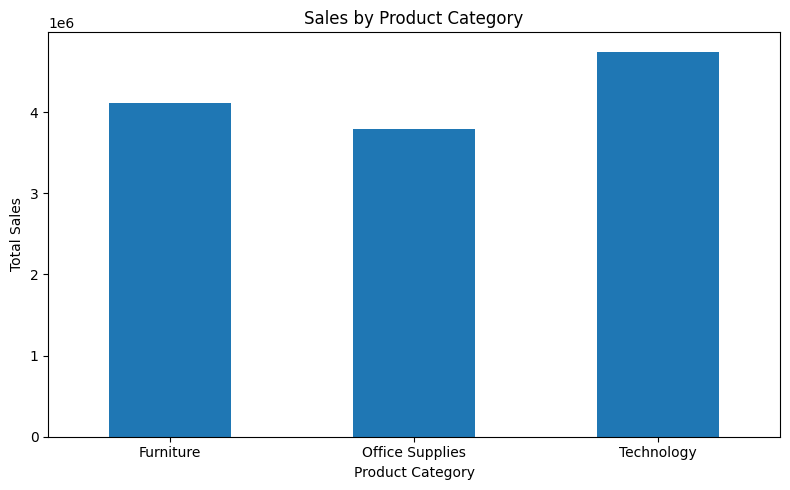

In [ ]:
category_sales.plot(kind='bar', figsize=(8, 5))

plt.title('Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
category_profit = df.groupby('Category')['Profit'].sum()

print(category_profit.sort_values(ascending=False).round(2))

Category
Technology         663778.73
Office Supplies    518473.83
Furniture          285204.72
Name: Profit, dtype: float64


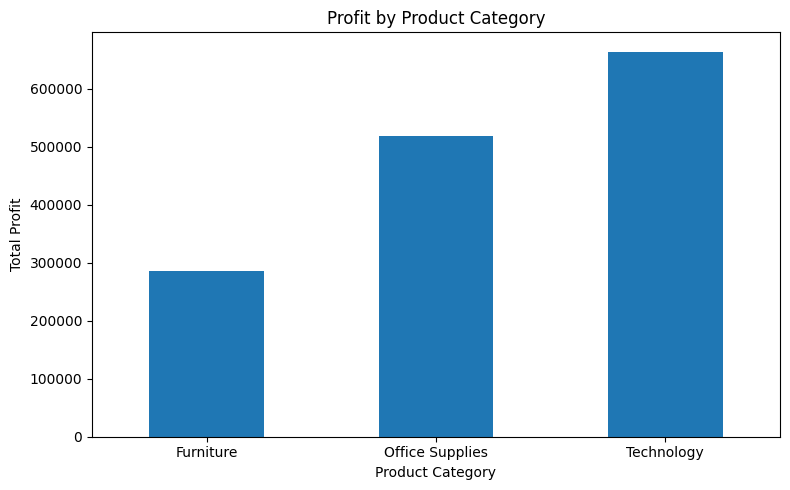

In [ ]:
category_profit.plot(kind='bar', figsize=(8, 5))

plt.title('Profit by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 7. Regional Performance Analysis

Sales and profit are analysed across different geographical regions to identify high-performing and low-performing markets.


In [ ]:
region_sales = df.groupby('Region')['Sales'].sum()

print(region_sales.sort_values(ascending=False).round(2))

Region
Central           2822302.52
South             1600907.04
North             1248165.60
Oceania           1100184.61
Southeast Asia     884423.17
North Asia         848309.78
EMEA               806161.31
Africa             783773.21
Central Asia       752826.57
West               725457.82
East               678781.24
Caribbean          324280.86
Canada              66928.17
Name: Sales, dtype: float64


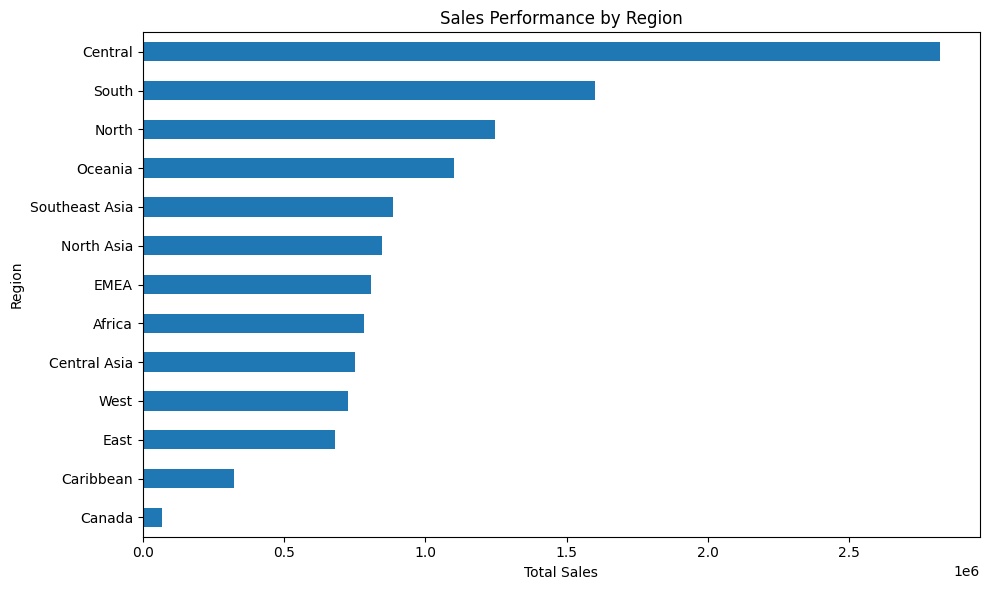

In [ ]:
region_sales.sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Sales Performance by Region')
plt.xlabel('Total Sales')
plt.ylabel('Region')
plt.tight_layout()
plt.show()

In [ ]:
region_profit = df.groupby('Region')['Profit'].sum()

print(region_profit.sort_values(ascending=False).round(2))

Region
Central           311403.98
North             194597.95
North Asia        165578.42
South             140355.77
Central Asia      132480.19
Oceania           120089.11
West              108418.45
East               91522.78
Africa             88871.63
EMEA               43897.97
Caribbean          34571.32
Southeast Asia     17852.33
Canada             17817.39
Name: Profit, dtype: float64


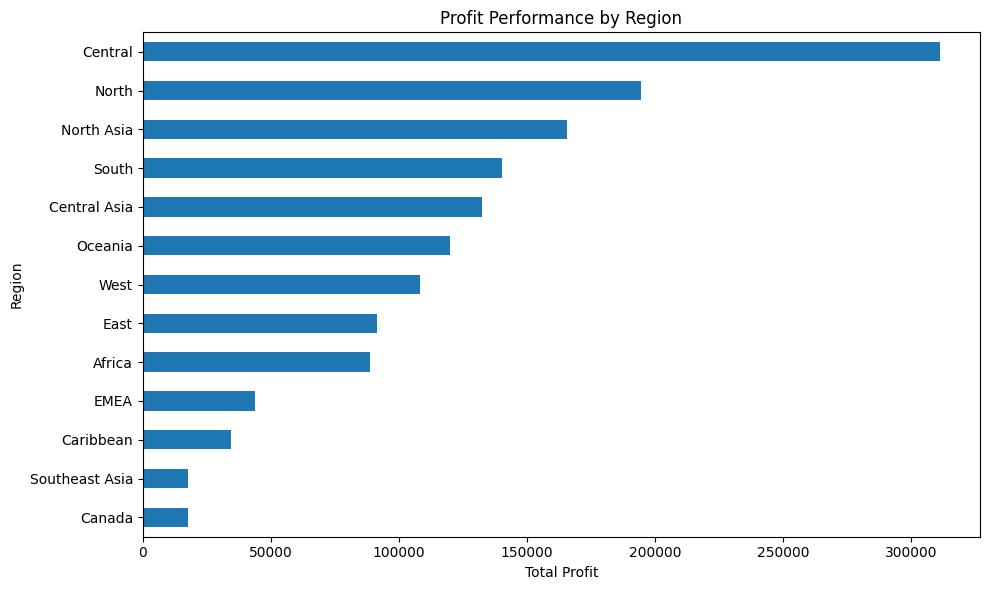

In [ ]:
region_profit.sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Profit Performance by Region')
plt.xlabel('Total Profit')
plt.ylabel('Region')
plt.tight_layout()
plt.show()


## 8. Customer Segment Analysis

Customer segments are analysed to understand their contribution to overall sales and profit.


In [ ]:
segment_sales = df.groupby('Segment')['Sales'].sum()

print(segment_sales.sort_values(ascending=False).round(2))

Segment
Consumer       6507949.42
Corporate      3824697.52
Home Office    2309854.97
Name: Sales, dtype: float64


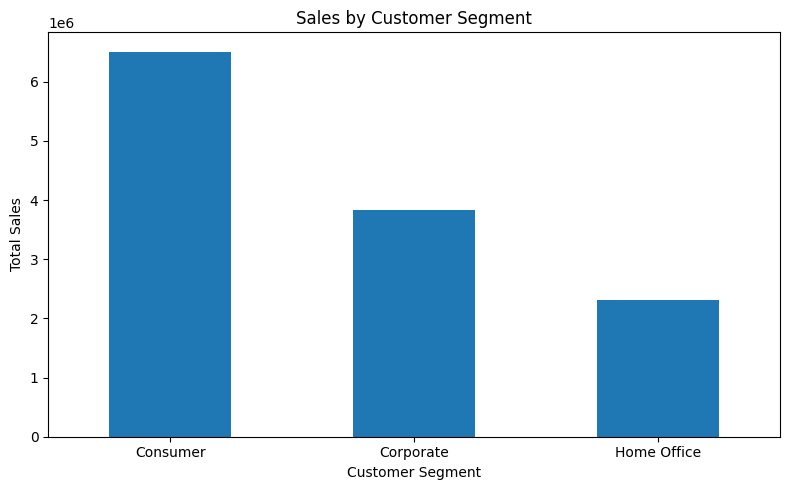

In [ ]:
segment_sales.plot(kind='bar', figsize=(8, 5))

plt.title('Sales by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
segment_profit = df.groupby('Segment')['Profit'].sum()

print(segment_profit.sort_values(ascending=False).round(2))

Segment
Consumer       749239.78
Corporate      441208.33
Home Office    277009.18
Name: Profit, dtype: float64


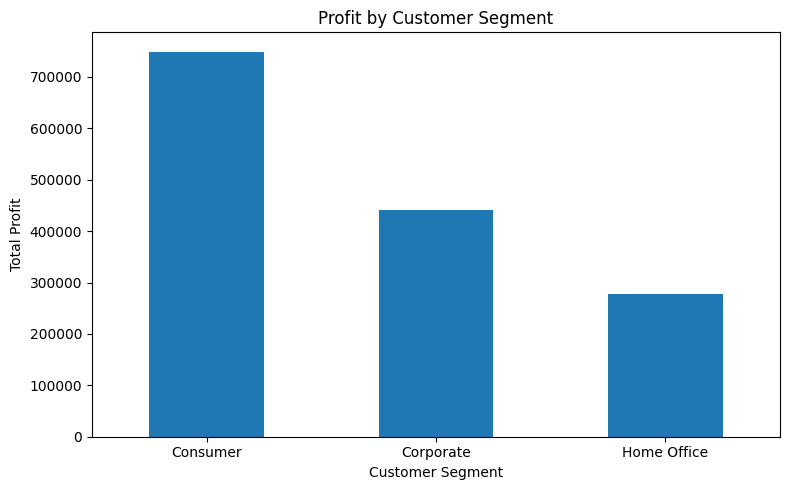

In [ ]:
segment_profit.plot(kind='bar', figsize=(8, 5))

plt.title('Profit by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
subcategory_sales = df.groupby('Sub-Category')['Sales'].sum()

print(subcategory_sales.sort_values(ascending=False).round(2))

Sub-Category
Phones         1706824.14
Copiers        1509436.27
Chairs         1501681.76
Bookcases      1466572.24
Storage        1127085.86
Appliances     1011064.30
Machines        779060.07
Tables          757041.92
Accessories     749237.02
Binders         461911.51
Furnishings     385578.26
Art             372091.97
Paper           244291.72
Supplies        243074.22
Envelopes       170904.30
Fasteners        83242.32
Labels           73404.03
Name: Sales, dtype: float64


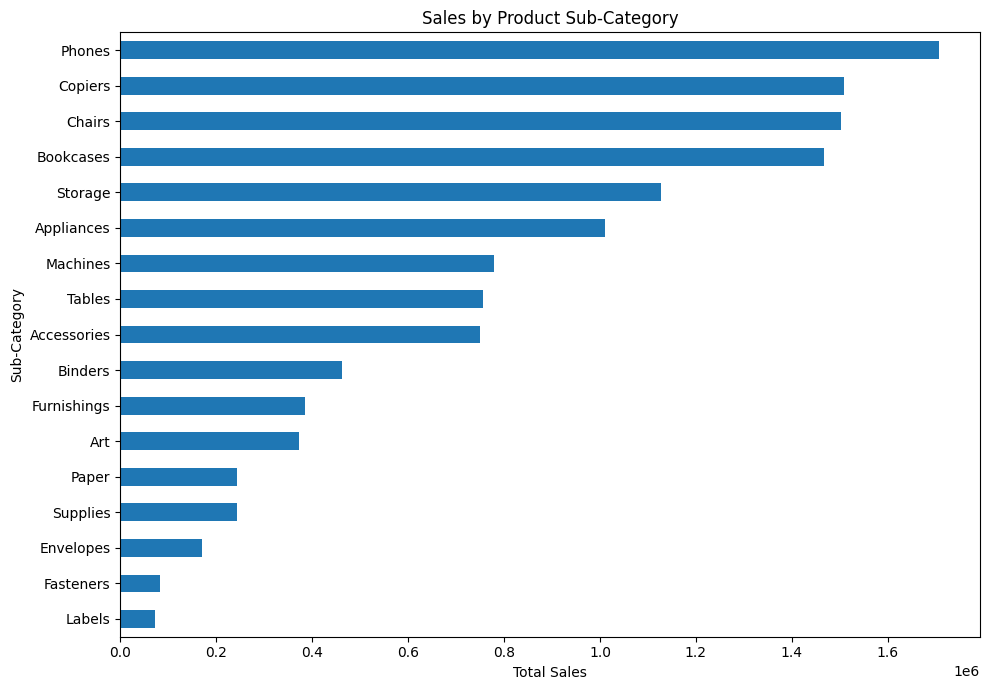

In [ ]:
subcategory_sales.sort_values().plot(
    kind='barh',
    figsize=(10, 7)
)

plt.title('Sales by Product Sub-Category')
plt.xlabel('Total Sales')
plt.ylabel('Sub-Category')
plt.tight_layout()
plt.show()

In [ ]:
subcategory_profit = df.groupby('Sub-Category')['Profit'].sum()

print(subcategory_profit.sort_values(ascending=False).round(2))

Sub-Category
Copiers        258567.55
Phones         216717.01
Bookcases      161924.42
Appliances     141680.59
Chairs         140396.27
Accessories    129626.31
Storage        108461.49
Binders         72449.85
Paper           59207.68
Machines        58867.87
Art             57953.91
Furnishings     46967.43
Envelopes       29601.12
Supplies        22583.26
Labels          15010.51
Fasteners       11525.42
Tables         -64083.39
Name: Profit, dtype: float64


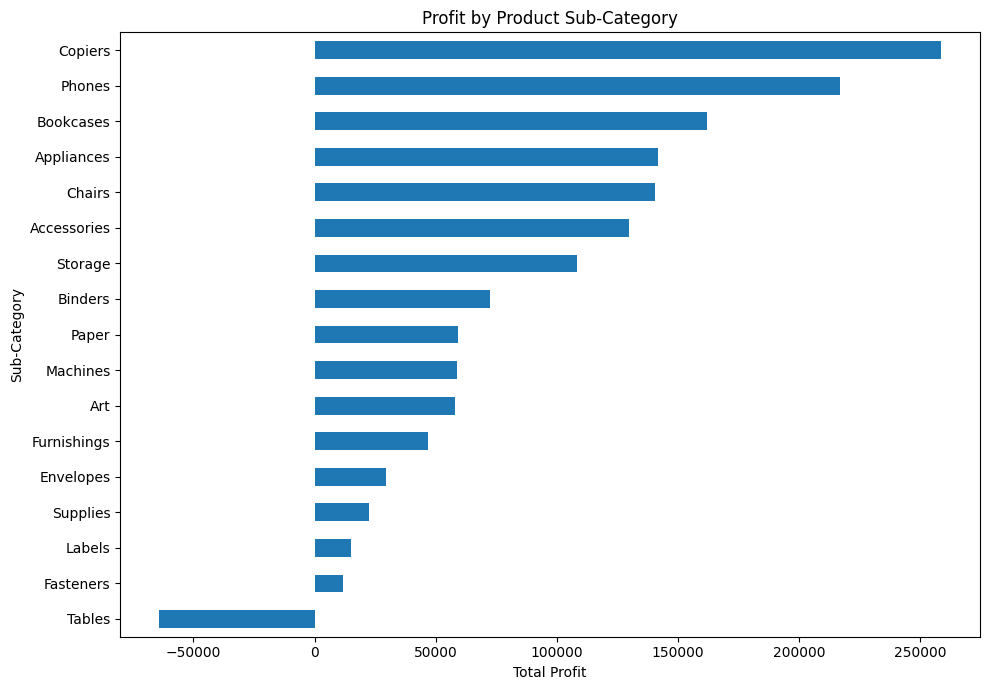

In [ ]:
subcategory_profit.sort_values().plot(
    kind='barh',
    figsize=(10, 7)
)

plt.title('Profit by Product Sub-Category')
plt.xlabel('Total Profit')
plt.ylabel('Sub-Category')
plt.tight_layout()
plt.show()


## 9. Shipping and Discount Analysis

Shipping methods are compared based on sales performance. The relationship between discount levels and average profit is also examined.


In [ ]:
shipping_sales = df.groupby('Ship Mode')['Sales'].sum()

print(shipping_sales.sort_values(ascending=False).round(2))

Ship Mode
Standard Class    7578652.11
Second Class      2565671.68
First Class       1830976.14
Same Day           667201.98
Name: Sales, dtype: float64


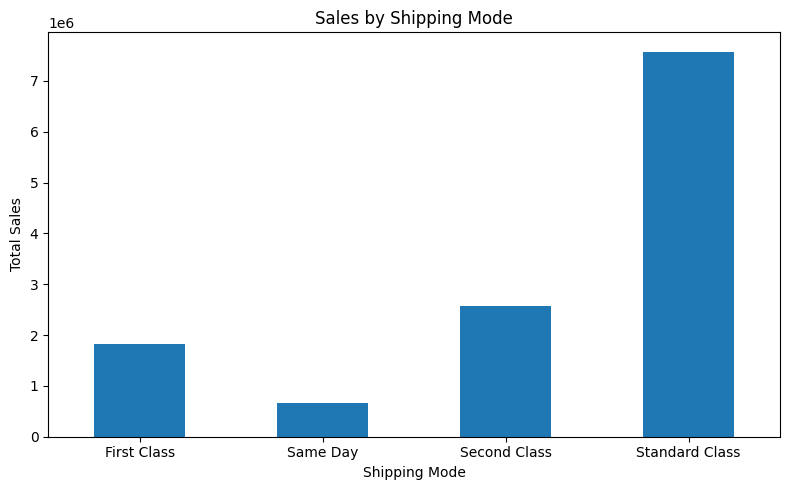

In [ ]:
shipping_sales.plot(kind='bar', figsize=(8, 5))

plt.title('Sales by Shipping Mode')
plt.xlabel('Shipping Mode')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
discount_profit = df.groupby('Discount')['Profit'].mean()

print(discount_profit.round(2))

Discount
0.000      61.04
0.002     125.76
0.070     140.99
0.100      63.68
0.150      50.60
0.170      38.32
0.200      23.55
0.202     -14.52
0.250       4.04
0.270      -4.32
0.300     -57.90
0.320     -88.56
0.350    -116.14
0.370     -78.46
0.400     -45.25
0.402    -109.91
0.450     -41.61
0.470     -42.98
0.500     -97.14
0.550    -315.07
0.570    -526.13
0.600     -81.73
0.602    -213.28
0.650    -366.00
0.700    -104.34
0.800    -122.20
0.850   -1534.33
Name: Profit, dtype: float64


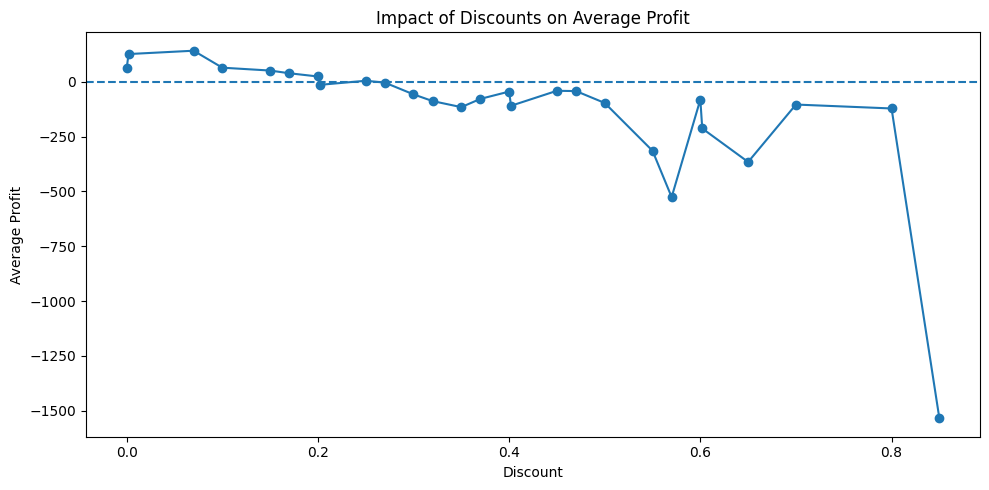

In [ ]:
discount_profit.plot(kind='line', marker='o', figsize=(10, 5))

plt.title('Impact of Discounts on Average Profit')
plt.xlabel('Discount')
plt.ylabel('Average Profit')
plt.axhline(y=0, linestyle='--')
plt.tight_layout()
plt.show()


## 10. Order Priority Analysis

Sales are analysed based on order priority levels to understand the distribution of business revenue across different priority categories.


In [ ]:
priority_sales = df.groupby('Order Priority')['Sales'].sum()

print(priority_sales.sort_values(ascending=False).round(2))

Order Priority
Medium      7280892.37
High        3807548.14
Critical     986235.46
Low          567825.93
Name: Sales, dtype: float64


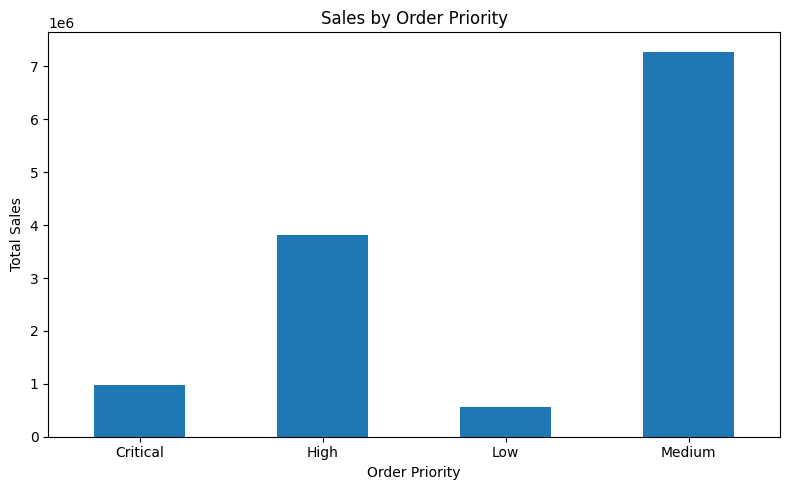

In [ ]:
priority_sales.plot(kind='bar', figsize=(8, 5))

plt.title('Sales by Order Priority')
plt.xlabel('Order Priority')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 11. Key Findings

- Total sales reached 12.64 million, with an overall profit of 1.47 million.
- Sales increased consistently from 2011 to 2014.
- December recorded the highest monthly sales.
- Technology was the highest-selling and most profitable product category.
- Central region recorded the highest sales and profit.
- Consumer customers contributed the highest sales and profit.
- Copiers generated the highest profit among sub-categories.
- Tables recorded a loss.
- Higher discount levels were generally associated with lower average profit.
- Standard Class shipping contributed the highest sales.

## 12. Conclusion

The Retail Sales Performance Analysis provided useful insights into business performance, sales trends, product profitability, customer segments, and regional performance.

The analysis identified key areas of strength and potential improvement, particularly in product profitability and discount management.

These findings can help businesses make better decisions, improve profitability, and develop effective sales strategies.
